[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/02_linear-regression.ipynb)

*Machine Learning from Scratch · Notebook 2 of 10*

# Linear Regression

The first model to learn: fitting a line by least squares and by gradient descent, multiple features, regression metrics, polynomial features, overfitting, and Ridge / Lasso regularisation.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Linear regression draws the line that misses the points by the smallest total amount.

**What interviewers really test here:** Assumptions, the closed form vs gradient descent, regularisation, and reading coefficients.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. The model: a straight line *(Basics)*
- [ ] 2. Fitting a line by hand *(Basics)*
- [ ] 3. Measuring regression error *(Core)*
- [ ] 4. Many features and gradient descent *(Core)*
- [ ] 5. Where the slope formula comes from *(Core)*
- [ ] 6. Gradient descent, step by step *(Core)*
- [ ] 7. Curves, overfitting and the bias–variance trade-off *(Advanced)*
- [ ] 8. Regularisation: Ridge and Lasso *(Advanced)*
- [ ] 9. Reading residuals: is the model right? *(Advanced)*
- [ ] 10. Ridge and Lasso, worked by hand *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Model and estimation

ŷ = Xw (with a column of 1s for the intercept). Ordinary least squares minimises ‖y − Xw‖², giving the **normal equations** XᵀXw = Xᵀy and w = (XᵀX)⁻¹Xᵀy when XᵀX is invertible. Geometrically, ŷ is the projection of y onto the column space of X. Computed in practice by QR/SVD (`lstsq`) or by gradient descent for very large data.



Maximum-likelihood view: if y = Xw + ε with ε ~ N(0, σ²), least squares is the MLE.

### Assumptions (for valid inference)

1. **Linearity**: E[y | x] is linear in the parameters (features may be transformed).
2. **Independence** of errors.
3. **Homoscedasticity**: constant error variance (no funnel shape in residuals).
4. **Normality** of errors (matters for confidence intervals, not for prediction).
5. No perfect **multicollinearity** among features (check correlations / VIF).



Diagnose with residual plots; fix with transformations, interaction or polynomial terms, robust or regularised regression.

### Metrics

| Metric | Formula | Notes |
| --- | --- | --- |
| MSE | (1/n)Σ(y − ŷ)² | differentiable, outlier-sensitive |
| RMSE | √MSE | same units as y |
| MAE | (1/n)Σ\|y − ŷ\| | robust; median-optimal |
| MAPE | (1/n)Σ\|y − ŷ\|/\|y\| | undefined at y = 0, asymmetric |
| R² | 1 − SS\_res/SS\_tot | can be negative on test data |
| Adjusted R² | 1 − (1 − R²)(n − 1)/(n − p − 1) | penalises extra features |

### Regularisation

|   | Ridge | Lasso | Elastic Net |
| --- | --- | --- | --- |
| Penalty | α‖w‖₂² | α‖w‖₁ | α(ρ‖w‖₁ + (1 − ρ)‖w‖₂²/2) |
| Solution | closed form (XᵀX + αI)⁻¹Xᵀy | coordinate descent with soft-thresholding | coordinate descent |
| Sparsity | no | yes | yes |
| Correlated features | shares weight among them | picks one arbitrarily | groups them |



Bayesian view: Ridge = Gaussian prior on weights, Lasso = Laplace prior. The intercept is not penalised; features must be scaled.

### Bias–variance decomposition

Expected test error = **bias²** + **variance** + irreducible noise. Simple models: high bias, low variance. Flexible models: low bias, high variance. Regularisation, more data, fewer features and ensembling reduce variance; richer features or models reduce bias.

### When to use linear regression

| Good for | Weak at |
| --- | --- |
| a quick, explainable baseline; small data; many features with Ridge; fast predictions; extrapolating a true trend | curves and interactions you didn't add as features; outliers (with squared error); correlated features if you need to interpret coefficients |



Variants: Huber and RANSAC (robust to outliers), Poisson regression (counts), quantile regression (predicts a percentile instead of the mean).

---
# Part 2: Lessons, step by step

## Lesson 1: The model: a straight line

*Level: Basics*

Linear regression predicts a number with a weighted sum of the features:



**ŷ = w₁x₁ + w₂x₂ + … + b**



With one feature that's a straight line: **w** is the slope (how much ŷ changes per unit of x) and **b** is the intercept. "Training" means choosing w and b. The usual choice is **least squares**: make the sum of squared vertical distances from the points to the line as small as possible.



For one feature there's a formula: slope = Σ(x − x̄)(y − ȳ)/Σ(x − x̄)², intercept = ȳ − slope·x̄.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

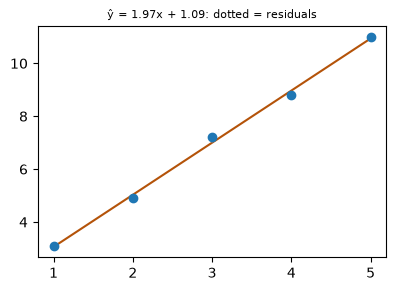

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso


def least_squares_picture():
    x = np.array([1, 2, 3, 4, 5])
    y = np.array([3.1, 4.9, 7.2, 8.8, 11.0])
    model = LinearRegression().fit(x.reshape(-1, 1), y)
    pred = model.predict(x.reshape(-1, 1))
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(x, y, zorder=3)
    ax.plot(x, pred, color="#b45309")
    for a, b, p in zip(x, y, pred):
        ax.plot([a, a], [b, p], ":", color="gray")
    ax.set_title(f"ŷ = {model.coef_[0]:.2f}x + {model.intercept_:.2f}: dotted = residuals", fontsize=8)


least_squares_picture()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 2: Fitting a line by hand

*Level: Basics*

Let's fit y = wx + b to three points, doing every step: (1, 2), (2, 4), (3, 5).



#### Step 1: find the means



x̄ = 2 and ȳ = 11/3 = 3.667.



#### Step 2: slope and intercept



<table><tr><th>x</th><th>y</th><th>x − x̄</th><th>y − ȳ</th><th>(x − x̄)(y − ȳ)</th><th>(x − x̄)²</th></tr> <tr><td>1</td><td>2</td><td>−1</td><td>−1.667</td><td>1.667</td><td>1</td></tr> <tr><td>2</td><td>4</td><td>0</td><td>0.333</td><td>0</td><td>0</td></tr> <tr><td>3</td><td>5</td><td>1</td><td>1.333</td><td>1.333</td><td>1</td></tr> <tr><td colspan="4"><b>Sum</b></td><td><b>3</b></td><td><b>2</b></td></tr></table>



Slope w = 3 / 2 = **1.5**. Intercept b = 3.667 − 1.5 × 2 = **0.667**.



#### Step 3: check the fit



| x | y | ŷ | Residual y − ŷ | Squared |
| --- | --- | --- | --- | --- |
| 1 | 2 | 2.167 | −0.167 | 0.028 |
| 2 | 4 | 3.667 | 0.333 | 0.111 |
| 3 | 5 | 5.167 | −0.167 | 0.028 |



The squared errors total 0.167. Predicting the mean every time gives a total of 4.667. So R² = 1 − 0.167 / 4.667 = **0.964**: the line explains 96.4% of the variation.



**Why it always works:** the residuals add up to exactly 0, and no other straight line gets a smaller squared total.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def line_by_hand():
    x = np.array([1.0, 2.0, 3.0])
    y = np.array([2.0, 4.0, 5.0])
    x_mean, y_mean = x.mean(), y.mean()
    top = ((x - x_mean) * (y - y_mean)).sum()
    bottom = ((x - x_mean) ** 2).sum()
    slope = top / bottom
    intercept = y_mean - slope * x_mean
    pred = slope * x + intercept
    residuals = y - pred
    sse = (residuals ** 2).sum()
    sst = ((y - y_mean) ** 2).sum()
    r2 = 1 - sse / sst


line_by_hand()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q7](#q7), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 3: Measuring regression error

*Level: Core*

| Metric | Formula | Read as |
| --- | --- | --- |
| **MSE** | mean (y − ŷ)² | squared units; punishes big errors |
| **RMSE** | √MSE | typical error in the target's own units |
| **MAE** | mean \|y − ŷ\| | typical error; less sensitive to outliers |
| **MAPE** | mean \|y − ŷ\|/\|y\| | percentage error (bad near y = 0) |
| **R²** | 1 − SS\_res/SS\_tot | share of variance explained; 1 perfect, 0 = predicting the mean |
| Adjusted R² | penalises extra features | for comparing models with different feature counts |



Always report errors on the **test** set, and look at the **residuals**: a pattern in them (a curve, a funnel) means the model is missing something.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
import math


def metrics_demo():
    y = np.array([3, 5, 7, 9, 11])
    y_pred = np.array([2.8, 5.3, 6.9, 9.6, 10.4])
    errors = y - y_pred
    mse = (errors ** 2).mean()
    rmse = math.sqrt(mse)
    mae = np.abs(errors).mean()
    r2 = 1 - (errors ** 2).sum() / ((y - y.mean()) ** 2).sum()


metrics_demo()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q5](#q5), [Q6](#q6), [Q10](#q10), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 4: Many features and gradient descent

*Level: Core*

With d features we stack them into a matrix X (plus a column of 1s for b) and the least-squares weights solve the **normal equations** XᵀX·w = Xᵀy. sklearn's `LinearRegression` does this (via a stable least-squares solver).



For huge datasets or other models, we instead use **gradient descent** on the MSE — it reaches the same answer step by step. Coefficients tell you each feature's effect *holding the others fixed*; to compare their importance, standardise the features first.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

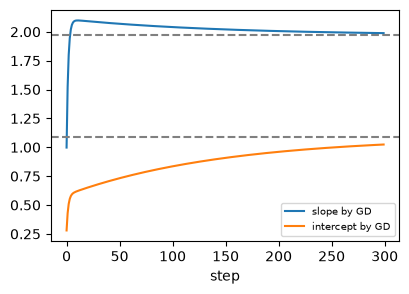

In [5]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso


def gd_convergence():
    x = np.array([1, 2, 3, 4, 5], dtype=float)
    y = np.array([3.1, 4.9, 7.2, 8.8, 11.0])
    m = b = 0.0
    path = []
    for _ in range(300):
        err = y - (m * x + b)
        m -= 0.02 * -2 * (x * err).mean()
        b -= 0.02 * -2 * err.mean()
        path.append((m, b))
    path = np.array(path)
    exact = LinearRegression().fit(x.reshape(-1, 1), y)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(path[:, 0], label="slope by GD")
    ax.plot(path[:, 1], label="intercept by GD")
    ax.axhline(exact.coef_[0], ls="--", color="gray")
    ax.axhline(exact.intercept_, ls="--", color="gray")
    ax.set_xlabel("step")
    ax.legend(fontsize=7)


gd_convergence()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q12](#q12), [Q15](#q15), [Q16](#q16), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 5: Where the slope formula comes from

*Level: Core*

You don't need to memorise the formula; it follows from one idea: **the bottom of a bowl is where the slope is zero.**



The total error L(w, b) = Σ(y − wx − b)² is a smooth bowl. Set both partial derivatives to zero:




1. **∂L/∂b = −2Σ(y − wx − b) = 0**, which gives b = ȳ − w·x̄. So the best line always passes through the point (x̄, ȳ).
2. **∂L/∂w = −2Σx(y − wx − b) = 0.** Substitute b and rearrange to get w = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)².



#### The same answer with matrices



With many features we write XᵀX·w = Xᵀy. For our three points, X has a column of 1s and a column of x:



```python
XᵀX = [[3,  6],     Xᵀy = [11,
       [6, 14]]            25]
det = 3·14 − 6·6 = 6
inverse = (1/6)·[[14, −6], [−6, 3]]
b = (14·11 − 6·25) / 6 = 4/6 = 0.667
w = (−6·11 + 3·25) / 6 = 9/6 = 1.5
```



Those match the hand calculation. Solving this system is what `LinearRegression` does, using a more numerically stable method.



**When it breaks:** if one feature is an exact copy or combination of others, XᵀX has no inverse. `lstsq` still returns an answer, and Ridge fixes the problem directly.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso


def normal_equation_by_hand():
    x = np.array([1.0, 2.0, 3.0])
    y = np.array([2.0, 4.0, 5.0])
    X = np.column_stack([np.ones(3), x])
    XtX = X.T @ X
    Xty = X.T @ y
    det = np.linalg.det(XtX)
    weights = np.linalg.inv(XtX) @ Xty
    same_answer = LinearRegression().fit(x.reshape(-1, 1), y)
    sklearn_weights = (same_answer.intercept_, same_answer.coef_[0])


normal_equation_by_hand()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 6: Gradient descent, step by step

*Level: Core*

Same three points, starting from w = b = 0 with learning rate 0.1. The gradients of the MSE are ∂/∂w = −2·mean(x·error) and ∂/∂b = −2·mean(error).



| Step | Errors | MSE | ∂/∂w | ∂/∂b | New w | New b |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 2, 4, 5 | 15 | −16.667 | −7.333 | 1.667 | 0.733 |
| 2 | −0.4, −0.067, −0.733 | 0.234 | 1.822 | 0.8 | 1.484 | 0.653 |
| 3 | −0.138, 0.378, −0.107 | 0.058 | −0.199 | −0.089 | 1.504 | 0.662 |



In three steps w is already near the true 1.5 and b near 0.667. Notice step 1 overshot (w went above 1.5) and step 2 corrected it.



#### The learning rate decides everything




- Too small: correct, but very slow.
- Good: the loss falls smoothly.
- Too large: each step overshoots further and the loss explodes.



**Normal equations or gradient descent?** The direct solution is exact and simple but gets expensive as features grow (about d³). Gradient descent scales to huge data and is the only option for neural networks.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

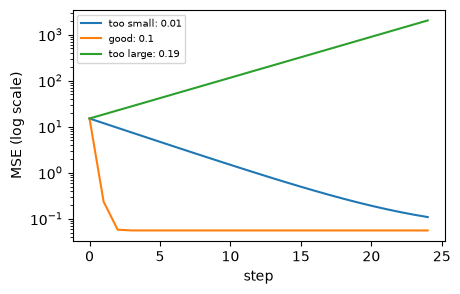

In [7]:
def learning_rates():
    x = np.array([1.0, 2.0, 3.0])
    y = np.array([2.0, 4.0, 5.0])
    fig, ax = plt.subplots(figsize=(4.8, 3))
    for lr, label in [(0.01, "too small: 0.01"), (0.1, "good: 0.1"), (0.19, "too large: 0.19")]:
        w = b = 0.0
        losses = []
        for _ in range(25):
            err = y - (w * x + b)
            losses.append((err ** 2).mean())
            w += lr * 2 * (x * err).mean()
            b += lr * 2 * err.mean()
        ax.plot(losses, label=label)
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_ylabel("MSE (log scale)")
    ax.legend(fontsize=7)


learning_rates()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 7: Curves, overfitting and the bias–variance trade-off

*Level: Advanced*

Add polynomial features (x², x³, …) and the "linear" model can fit curves. But more flexibility is not always better:




- **Underfitting** (high **bias**): too simple — high error on train *and* test.
- **Overfitting** (high **variance**): so flexible it fits the noise — low train error, high test error.



The sweet spot is found by checking error on data the model didn't train on. Test error typically falls, then rises again as complexity grows.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

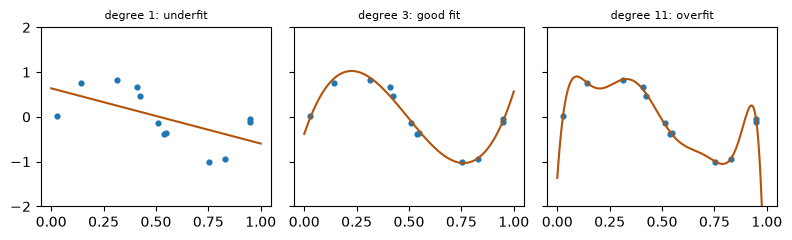

In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline


def overfit_demo():
    rng = np.random.default_rng(1)
    x = np.sort(rng.uniform(0, 1, 12))
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, 12)
    grid = np.linspace(0, 1, 200)
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.5), sharey=True)
    for ax, degree, name in zip(axes, [1, 3, 11], ["underfit", "good fit", "overfit"]):
        model = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(x.reshape(-1, 1), y)
        ax.scatter(x, y, s=12)
        ax.plot(grid, model.predict(grid.reshape(-1, 1)), color="#b45309")
        ax.set_ylim(-2, 2)
        ax.set_title(f"degree {degree}: {name}", fontsize=8)
    fig.tight_layout()


overfit_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 8: Regularisation: Ridge and Lasso

*Level: Advanced*

Regularisation adds a penalty on large weights to the loss, trading a little bias for much less variance:



| Model | Loss | Effect |
| --- | --- | --- |
| **Ridge** (L2) | MSE + α Σw² | shrinks all weights smoothly; great with correlated features |
| **Lasso** (L1) | MSE + α Σ\|w\| | sets some weights exactly to 0 → automatic feature selection |
| Elastic Net | both | a mix |



α is a hyper-parameter: α = 0 is plain regression, large α pushes weights to 0. Choose it with cross-validation (`RidgeCV`, `LassoCV`). Always scale features first, or the penalty treats them unfairly.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

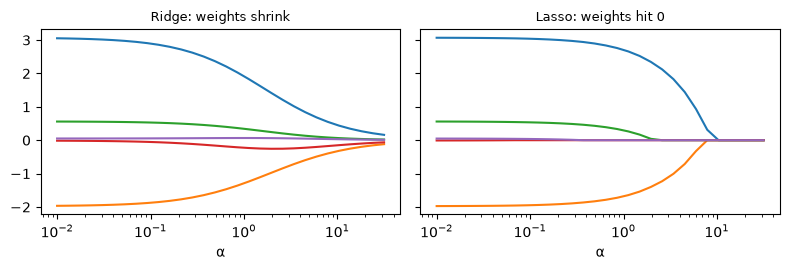

In [9]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso


def regularisation_paths():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(60, 5))
    y = X @ np.array([3, -2, 0.5, 0, 0]) + rng.normal(0, 0.5, 60)
    alphas = np.logspace(-2, 1.5, 30)
    ridge = np.array([Ridge(alpha=a * 20).fit(X, y).coef_ for a in alphas])
    lasso = np.array([Lasso(alpha=a / 5).fit(X, y).coef_ for a in alphas])
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
    left.semilogx(alphas, ridge)
    left.set_title("Ridge: weights shrink", fontsize=9)
    right.semilogx(alphas, lasso)
    right.set_title("Lasso: weights hit 0", fontsize=9)
    left.set_xlabel("α")
    right.set_xlabel("α")
    fig.tight_layout()


regularisation_paths()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q8](#q8), [Q18](#q18), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 9: Reading residuals: is the model right?

*Level: Advanced*

A high R² doesn't prove the model is suitable. Plot residuals against predictions. **You want a shapeless cloud around zero.**



| Pattern | What it means | Try |
| --- | --- | --- |
| Curve (U shape) | the true relationship isn't straight | polynomial features, a log transform, or a non-linear model |
| Funnel widening to the right | errors grow with the value | model log(y) |
| A few huge points | outliers pull the line | check the data; try Huber regression or MAE |
| Waves over time | errors are correlated | add time features; use time-series methods |



#### Interpreting coefficients carefully




- A coefficient is the effect of a feature **holding the others fixed**, in that feature's units.
- To compare importance, standardise features first.
- **Collinearity:** if two features nearly duplicate each other, their individual coefficients become unstable, even though predictions stay fine.
- A coefficient shows association, not cause. Advertising and sales may both rise at Diwali.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

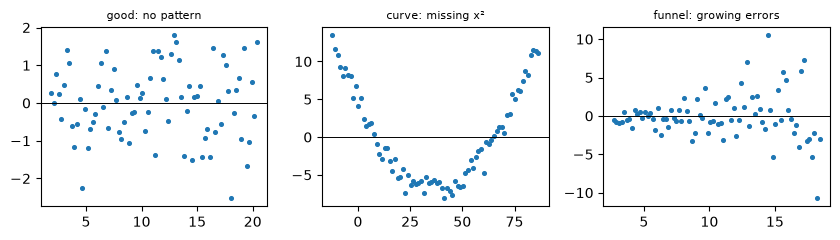

In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso


def residual_patterns():
    rng = np.random.default_rng(0)
    x = np.linspace(1, 10, 80)
    cases = [("good: no pattern", 2 * x + rng.normal(0, 1, 80)), ("curve: missing x²", x ** 2 + rng.normal(0, 1, 80)), ("funnel: growing errors", 2 * x + rng.normal(0, 0.4 * x))]
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.5))
    for ax, (name, y) in zip(axes, cases):
        model = LinearRegression().fit(x.reshape(-1, 1), y)
        pred = model.predict(x.reshape(-1, 1))
        ax.scatter(pred, y - pred, s=7)
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(name, fontsize=8)
    fig.tight_layout()


residual_patterns()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q15](#q15), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 10: Ridge and Lasso, worked by hand

*Level: Advanced*

Use the same three points. Centring gives Σxy = 3 and Σx² = 2.



#### Ridge: slope = Σxy / (Σx² + α)



| α | Slope | Intercept |
| --- | --- | --- |
| 0 | 3 / 2 = 1.5 | 0.667 |
| 1 | 3 / 3 = 1.0 | 1.667 |



The penalty sits in the denominator, so the slope shrinks but never reaches 0.



#### Lasso: slope = soft-threshold(ρ, α) / z



Here ρ = Σxy / n = 1 and z = Σx² / n = 0.667. Soft-thresholding subtracts α from |ρ|, stopping at 0.



| α | Thresholded ρ | Slope |
| --- | --- | --- |
| 0.5 | 0.5 | 0.5 / 0.667 = 0.75 |
| 1.2 | 0 (cut off) | **exactly 0** |



That's why Lasso selects features: once the penalty beats a feature's usefulness, its weight becomes exactly zero.



#### Practical guide




- Start with Ridge when most features probably help a little.
- Use Lasso when you expect only a few to matter or want a simpler model.
- Use Elastic Net when features are correlated and you still want some sparsity.
- Always scale first; the intercept is never penalised.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
import math


def shrink_by_hand():
    sxy, sxx, n = 3.0, 2.0, 3
    ridge_slopes = {alpha: sxy / (sxx + alpha) for alpha in [0, 1, 10]}
    rho, z = sxy / n, sxx / n
    lasso_slopes = {alpha: math.copysign(max(abs(rho) - alpha, 0.0), rho) / z for alpha in [0.5, 1.2]}


shrink_by_hand()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q18](#q18), [Q19](#q19), [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error)

import math

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.pipeline import make_pipeline


<a id="q1"></a>
### Q1. Fit a Line

🟢 Warm-up · *Least squares*

Fit y ≈ slope·x + intercept. Return (slope, intercept) rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0]` → `(1.97, 1.09)`
- `x = [0, 1, 2], y = [1, 3, 5]` → `(2.0, 1.0)`

In [ ]:
def fit_line(x, y):
    """
    Fit y ≈ slope·x + intercept. Return (slope, intercept) rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fit_line, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0]), (1.97, 1.09)),
    (([0, 1, 2], [1, 3, 5]), (2.0, 1.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

slope = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)², intercept = ȳ − slope·x̄.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LinearRegression().fit(X, y)`, read `coef_` and `intercept_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** slope = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)², intercept = ȳ − slope·x̄.

```python
def fit_line(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    slope = sum((a - mx) * (b - my) for a, b in zip(x, y)) / sum((a - mx) ** 2 for a in x)
    return (round(slope, 4), round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LinearRegression().fit(X, y)`, read `coef_` and `intercept_`.

```python
def fit_line(x, y):
    model = LinearRegression().fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0], 4), round(model.intercept_, 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: slope = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)², intercept = ȳ − slope·x̄. That costs O(n) time and O(1) space."

"I can do better: `LinearRegression().fit(X, y)`, read `coef_` and `intercept_`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/fit-a-line)

<a id="q2"></a>
### Q2. Predict New Values

🟢 Warm-up · *Using the fitted line*

Fit on (x, y) and return predictions for new\_x, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], new_x = [6, 0]` → `[12.91, 1.09]`

In [ ]:
def predict(x, y, new_x):
    """
    Fit on (x, y) and return predictions for new_x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predict, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], [6, 0]), [12.91, 1.09]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit the slope and intercept by hand, then apply them.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`model.predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Fit the slope and intercept by hand, then apply them.

```python
def predict(x, y, new_x):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    slope = sum((a - mx) * (b - my) for a, b in zip(x, y)) / sum((a - mx) ** 2 for a in x)
    intercept = my - slope * mx
    return [round(slope * v + intercept, 4) for v in new_x]
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `model.predict`.

```python
def predict(x, y, new_x):
    model = LinearRegression().fit(np.array(x).reshape(-1, 1), y)
    return model.predict(np.array(new_x).reshape(-1, 1)).round(4)
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit the slope and intercept by hand, then apply them. That costs O(n + m) time and O(m) space."

"I can do better: `model.predict`. That's O(n + m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/predict-new-values)

<a id="q3"></a>
### Q3. Mean Squared Error

🟢 Warm-up · *MSE*

Return the mean of (y − ŷ)², rounded to 4 decimals.

**Examples**

- `y = [3, 5, 7], y_pred = [2.5, 5, 8]` → `0.4167`
- `y = [1, 1], y_pred = [1, 1]` → `0.0`

In [ ]:
def mse(y, y_pred):
    """
    Return the mean of (y − ŷ)², rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mse, [
    (([3, 5, 7], [2.5, 5, 8]), 0.4167),
    (([1, 1], [1, 1]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: difference, square, average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`mean_squared_error(y, y_pred)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop: difference, square, average.

```python
def mse(y, y_pred):
    return round(sum((a - b) ** 2 for a, b in zip(y, y_pred)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `mean_squared_error(y, y_pred)`.

```python
def mse(y, y_pred):
    return round(mean_squared_error(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: difference, square, average. That costs O(n) time and O(1) space."

"I can do better: `mean_squared_error(y, y_pred)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/mean-squared-error)

<a id="q4"></a>
### Q4. Root Mean Squared Error

🟢 Warm-up · *RMSE — error in the target's units*

Return √MSE, rounded to 4 decimals.

**Examples**

- `y = [3, 5, 7], y_pred = [2.5, 5, 8]` → `0.6455`
- `y = [10, 20], y_pred = [13, 16]` → `3.5355`

In [ ]:
def rmse(y, y_pred):
    """
    Return √MSE, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rmse, [
    (([3, 5, 7], [2.5, 5, 8]), 0.6455),
    (([10, 20], [13, 16]), 3.5355),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute MSE by hand and take the square root.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.sqrt(mean_squared_error(…))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute MSE by hand and take the square root.

```python
def rmse(y, y_pred):
    return round(math.sqrt(sum((a - b) ** 2 for a, b in zip(y, y_pred)) / len(y)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.sqrt(mean_squared_error(…))`.

```python
def rmse(y, y_pred):
    return round(np.sqrt(mean_squared_error(y, y_pred)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute MSE by hand and take the square root. That costs O(n) time and O(1) space."

"I can do better: `np.sqrt(mean_squared_error(…))`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/root-mean-squared-error)

<a id="q5"></a>
### Q5. Mean Absolute Error

🟢 Warm-up · *MAE — robust to outliers*

Return the mean of |y − ŷ|, rounded to 4 decimals.

**Examples**

- `y = [3, 5, 7], y_pred = [2.5, 5, 8]` → `0.5`
- `y = [0, 0, 0, 100], y_pred = [0, 0, 0, 0]` → `25.0`

In [ ]:
def mae(y, y_pred):
    """
    Return the mean of |y − ŷ|, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mae, [
    (([3, 5, 7], [2.5, 5, 8]), 0.5),
    (([0, 0, 0, 100], [0, 0, 0, 0]), 25.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop of absolute differences.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`mean_absolute_error`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop of absolute differences.

```python
def mae(y, y_pred):
    return round(sum(abs(a - b) for a, b in zip(y, y_pred)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `mean_absolute_error`.

```python
def mae(y, y_pred):
    return round(mean_absolute_error(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop of absolute differences. That costs O(n) time and O(1) space."

"I can do better: `mean_absolute_error`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/mean-absolute-error)

<a id="q6"></a>
### Q6. Mean Absolute Percentage Error

🟢 Warm-up · *MAPE*

Return the mean of |y − ŷ| / |y| as a fraction, rounded to 4 decimals.

**Examples**

- `y = [100, 200, 50], y_pred = [110, 180, 50]` → `0.0667`

In [ ]:
def mape(y, y_pred):
    """
    Return the mean of |y − ŷ| / |y| as a fraction, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mape, [
    (([100, 200, 50], [110, 180, 50]), 0.0667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop of relative errors.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`mean_absolute_percentage_error` (returns a fraction, not %).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop of relative errors.

```python
def mape(y, y_pred):
    return round(sum(abs(a - b) / abs(a) for a, b in zip(y, y_pred)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `mean_absolute_percentage_error` (returns a fraction, not %).

```python
def mape(y, y_pred):
    return round(mean_absolute_percentage_error(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop of relative errors. That costs O(n) time and O(1) space."

"I can do better: `mean_absolute_percentage_error` (returns a fraction, not %). That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/mean-absolute-percentage-error)

<a id="q7"></a>
### Q7. Residuals

🟢 Warm-up · *What the line missed*

Fit a line to (x, y) and return the residuals y − ŷ, rounded to 4 decimals. They always sum to ~0.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0]` → `[0.04, -0.13, 0.2, -0.17, 0.06]`

In [ ]:
def residuals(x, y):
    """
    Fit a line to (x, y) and return the residuals y − ŷ, rounded to 4 decimals.
    They always sum to ~0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(residuals, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0]), [0.04, -0.13, 0.2, -0.17, 0.06]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit by hand, subtract predictions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`y - model.predict(X)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Fit by hand, subtract predictions.

```python
def residuals(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    slope = sum((a - mx) * (b - my) for a, b in zip(x, y)) / sum((a - mx) ** 2 for a in x)
    intercept = my - slope * mx
    return [round(b - (slope * a + intercept), 4) + 0.0 for a, b in zip(x, y)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `y - model.predict(X)`.

```python
def residuals(x, y):
    X = np.array(x).reshape(-1, 1)
    model = LinearRegression().fit(X, y)
    return (np.array(y) - model.predict(X)).round(4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit by hand, subtract predictions. That costs O(n) time and O(n) space."

"I can do better: `y - model.predict(X)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/residuals)

<a id="q8"></a>
### Q8. Ridge Path: Stronger Penalty, Smaller Slope

🟢 Warm-up · *Effect of α*

Return the Ridge slope for each α in alphas, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alphas = [0.01, 1, 10, 100]` → `[1.968, 1.7909, 0.985, 0.1791]`

In [ ]:
def ridge_path(x, y, alphas):
    """
    Return the Ridge slope for each α in alphas, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ridge_path, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], [0.01, 1, 10, 100]), [1.968, 1.7909, 0.985, 0.1791]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Closed form for each α.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit `Ridge` once per α.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Closed form for each α.

```python
def ridge_path(x, y, alphas):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    sxy = sum((a - mx) * (b - my) for a, b in zip(x, y))
    sxx = sum((a - mx) ** 2 for a in x)
    return [round(sxy / (sxx + a), 4) for a in alphas]
```

**Cost:** O(k·n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit `Ridge` once per α.

```python
def ridge_path(x, y, alphas):
    X = np.array(x).reshape(-1, 1)
    return [round(Ridge(alpha=a).fit(X, y).coef_[0], 4) for a in alphas]
```

**Cost:** O(k·n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Closed form for each α. That costs O(k·n) time and O(k) space."

"I can do better: Fit `Ridge` once per α. That's O(k·n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/ridge-path-stronger-penalty-smaller-slope)

<a id="q9"></a>
### Q9. Multiple Linear Regression

🟡 Interview standard · *Several features*

Fit y ≈ b + w₁x₁ + w₂x₂ + … Return [b, w₁, w₂, …] rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 1], [3, 2], [4, 3], [5, 5]], y = [6, 8, 12, 16, 22]` → `[2.0, 2.0, 2.0]`
- `X = [[0, 1], [1, 0], [1, 1], [2, 1]], y = [3, 2, 5, 7]` → `[0.0, 2.0, 3.0]`

In [ ]:
def multi_fit(X, y):
    """
    Fit y ≈ b + w₁x₁ + w₂x₂ + … Return [b, w₁, w₂, …] rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(multi_fit, [
    (([[1, 1], [2, 1], [3, 2], [4, 3], [5, 5]], [6, 8, 12, 16, 22]), [2.0, 2.0, 2.0]),
    (([[0, 1], [1, 0], [1, 1], [2, 1]], [3, 2, 5, 7]), [0.0, 2.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add a column of 1s and solve the normal equations XᵀX·w = Xᵀy with NumPy.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LinearRegression`: intercept\_ and coef\_.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Add a column of 1s and solve the normal equations XᵀX·w = Xᵀy with NumPy.

```python
def multi_fit(X, y):
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    w = np.linalg.solve(A.T @ A, A.T @ np.array(y, dtype=float))
    return w.round(4) + 0.0
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LinearRegression`: intercept\_ and coef\_.

```python
def multi_fit(X, y):
    model = LinearRegression().fit(X, y)
    return np.concatenate([[model.intercept_], model.coef_]).round(4) + 0.0
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add a column of 1s and solve the normal equations XᵀX·w = Xᵀy with NumPy. That costs O(n·d² + d³) time and O(d²) space."

"I can do better: `LinearRegression`: intercept\_ and coef\_. That's O(n·d²) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/multiple-linear-regression)

<a id="q10"></a>
### Q10. R² Score

🟡 Interview standard · *Share of variance explained*

Return R² = 1 − SS\_res/SS\_tot, rounded to 4 decimals. 1 is perfect, 0 is no better than predicting the mean.

**Examples**

- `y = [3, 5, 7, 9], y_pred = [2.8, 5.3, 6.9, 9.2]` → `0.991`
- `y = [1, 2, 3], y_pred = [2, 2, 2]` → `0.0`

In [ ]:
def r2(y, y_pred):
    """
    Return R² = 1 − SS_res/SS_tot, rounded to 4 decimals. 1 is perfect, 0 is no
    better than predicting the mean.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(r2, [
    (([3, 5, 7, 9], [2.8, 5.3, 6.9, 9.2]), 0.991),
    (([1, 2, 3], [2, 2, 2]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two sums of squares in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`r2_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Two sums of squares in loops.

```python
def r2(y, y_pred):
    mean = sum(y) / len(y)
    ss_res = sum((a - b) ** 2 for a, b in zip(y, y_pred))
    ss_tot = sum((a - mean) ** 2 for a in y)
    return round(1 - ss_res / ss_tot, 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `r2_score`.

```python
def r2(y, y_pred):
    return round(r2_score(y, y_pred), 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two sums of squares in loops. That costs O(n) time and O(1) space."

"I can do better: `r2_score`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/r-score)

<a id="q11"></a>
### Q11. Adjusted R²

🟡 Interview standard · *Penalise useless features*

Given R², n samples and p features, return 1 − (1 − R²)(n − 1)/(n − p − 1), computing R² from y and ŷ. Rounded to 4 decimals.

**Examples**

- `y = [3, 5, 7, 9, 11, 13], y_pred = [2.8, 5.3, 6.9, 9.2, 11.4, 12.6], p = 2` → `0.9881`

In [ ]:
def adjusted_r2(y, y_pred, p):
    """
    Given R², n samples and p features, return 1 − (1 − R²)(n − 1)/(n − p − 1),
    computing R² from y and ŷ. Rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(adjusted_r2, [
    (([3, 5, 7, 9, 11, 13], [2.8, 5.3, 6.9, 9.2, 11.4, 12.6], 2), 0.9881),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

R² by hand, then the adjustment.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`r2_score`, then the adjustment (sklearn has no direct function).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** R² by hand, then the adjustment.

```python
def adjusted_r2(y, y_pred, p):
    n = len(y)
    mean = sum(y) / n
    r2 = 1 - sum((a - b) ** 2 for a, b in zip(y, y_pred)) / sum((a - mean) ** 2 for a in y)
    return round(1 - (1 - r2) * (n - 1) / (n - p - 1), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `r2_score`, then the adjustment (sklearn has no direct function).

```python
def adjusted_r2(y, y_pred, p):
    n = len(y)
    return round(1 - (1 - r2_score(y, y_pred)) * (n - 1) / (n - p - 1), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: R² by hand, then the adjustment. That costs O(n) time and O(1) space."

"I can do better: `r2_score`, then the adjustment (sklearn has no direct function). That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/adjusted-r)

<a id="q12"></a>
### Q12. Train by Gradient Descent

🟡 Interview standard · *Same answer, found by walking downhill*

Fit slope and intercept by gradient descent on the MSE (start at 0, learning rate 0.05, 5000 steps). Return (slope, intercept) rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0]` → `(1.97, 1.09)`
- `x = [0, 1, 2], y = [1, 3, 5]` → `(2.0, 1.0)`

In [ ]:
def gd_fit(x, y):
    """
    Fit slope and intercept by gradient descent on the MSE (start at 0, learning
    rate 0.05, 5000 steps). Return (slope, intercept) rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gd_fit, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0]), (1.97, 1.09)),
    (([0, 1, 2], [1, 3, 5]), (2.0, 1.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The training loop: predict, compute both gradients, step against them.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The exact least-squares answer from `LinearRegression` — gradient descent converges to it.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The training loop: predict, compute both gradients, step against them.

```python
def gd_fit(x, y):
    m = b = 0.0
    n = len(x)
    for _ in range(5000):
        dm = sum(-2 * a * (t - (m * a + b)) for a, t in zip(x, y)) / n
        db = sum(-2 * (t - (m * a + b)) for a, t in zip(x, y)) / n
        m -= 0.05 * dm
        b -= 0.05 * db
    return (round(m, 4), round(b, 4))
```

**Cost:** O(steps·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** The exact least-squares answer from `LinearRegression` — gradient descent converges to it.

```python
def gd_fit(x, y):
    model = LinearRegression().fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0], 4), round(model.intercept_, 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The training loop: predict, compute both gradients, step against them. That costs O(steps·n) time and O(1) space."

"I can do better: The exact least-squares answer from `LinearRegression` — gradient descent converges to it. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/train-by-gradient-descent)

<a id="q13"></a>
### Q13. Polynomial Regression

🟡 Interview standard · *Curves with a linear model*

Fit y ≈ a + bx + cx² and return predictions for new\_x, rounded to 4 decimals.

**Examples**

- `x = [0, 1, 2, 3, 4], y = [1, 2, 5, 10, 17], new_x = [5, -1]` → `[26.0, 2.0]`
- `x = [1, 2, 3, 4], y = [2, 3, 6, 11], new_x = [2.5]` → `[4.25]`

In [ ]:
def poly_predict(x, y, new_x):
    """
    Fit y ≈ a + bx + cx² and return predictions for new_x, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(poly_predict, [
    (([0, 1, 2, 3, 4], [1, 2, 5, 10, 17], [5, -1]), [26.0, 2.0]),
    (([1, 2, 3, 4], [2, 3, 6, 11], [2.5]), [4.25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`np.polyfit(x, y, 2)` and `np.polyval` (least squares on x, x²).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`make_pipeline(PolynomialFeatures(2), LinearRegression())`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `np.polyfit(x, y, 2)` and `np.polyval` (least squares on x, x²).

```python
def poly_predict(x, y, new_x):
    coeffs = np.polyfit(x, y, 2)
    return np.polyval(coeffs, new_x).round(4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `make_pipeline(PolynomialFeatures(2), LinearRegression())`.

```python
def poly_predict(x, y, new_x):
    model = make_pipeline(PolynomialFeatures(2), LinearRegression())
    model.fit(np.array(x).reshape(-1, 1), y)
    return model.predict(np.array(new_x).reshape(-1, 1)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `np.polyfit(x, y, 2)` and `np.polyval` (least squares on x, x²). That costs O(n) time and O(1) space."

"I can do better: `make_pipeline(PolynomialFeatures(2), LinearRegression())`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/polynomial-regression)

<a id="q14"></a>
### Q14. Ridge Regression (One Feature)

🟡 Interview standard · *L2 penalty shrinks the slope*

Minimise Σ(y − ŷ)² + α·slope². Return (slope, intercept), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 1.0` → `(1.7909, 1.6273)`
- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 10.0` → `(0.985, 4.045)`

In [ ]:
def ridge(x, y, alpha):
    """
    Minimise Σ(y − ŷ)² + α·slope². Return (slope, intercept), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ridge, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 1.0), (1.7909, 1.6273)),
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 10.0), (0.985, 4.045)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre x and y; slope = Σxc·yc / (Σxc² + α); intercept = ȳ − slope·x̄ (the intercept isn't penalised).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Ridge(alpha=α)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre x and y; slope = Σxc·yc / (Σxc² + α); intercept = ȳ − slope·x̄ (the intercept isn't penalised).

```python
def ridge(x, y, alpha):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    sxy = sum((a - mx) * (b - my) for a, b in zip(x, y))
    sxx = sum((a - mx) ** 2 for a in x)
    slope = sxy / (sxx + alpha)
    return (round(slope, 4), round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Ridge(alpha=α)`.

```python
def ridge(x, y, alpha):
    model = Ridge(alpha=alpha).fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0], 4), round(model.intercept_, 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre x and y; slope = Σxc·yc / (Σxc² + α); intercept = ȳ − slope·x̄ (the intercept isn't penalised). That costs O(n) time and O(1) space."

"I can do better: `Ridge(alpha=α)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/ridge-regression-one-feature)

<a id="q15"></a>
### Q15. Which Feature Matters Most?

🟡 Interview standard · *Standardised coefficients*

Standardise the features, fit a linear regression, and return the index of the feature with the largest |coefficient|.

**Examples**

- `X = [[1, 100], [2, 300], [3, 200], [4, 500], [5, 400]], y = [10, 25, 22, 41, 38]` → `1`

In [ ]:
def top_feature(X, y):
    """
    Standardise the features, fit a linear regression, and return the index of
    the feature with the largest |coefficient|.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_feature, [
    (([[1, 100], [2, 300], [3, 200], [4, 500], [5, 400]], [10, 25, 22, 41, 38]), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Standardise by hand, solve the normal equations with NumPy, compare |weights|.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`make_pipeline(StandardScaler(), LinearRegression())`, then argmax of |coef\_|.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Standardise by hand, solve the normal equations with NumPy, compare |weights|.

```python
def top_feature(X, y):
    A = np.array(X, dtype=float)
    A = (A - A.mean(axis=0)) / A.std(axis=0)
    A = np.column_stack([np.ones(len(A)), A])
    w = np.linalg.solve(A.T @ A, A.T @ np.array(y, dtype=float))[1:]
    return int(np.argmax(np.abs(w)))
```

**Cost:** O(n·d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `make_pipeline(StandardScaler(), LinearRegression())`, then argmax of |coef\_|.

```python
def top_feature(X, y):
    model = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    return int(np.argmax(np.abs(model[-1].coef_)))
```

**Cost:** O(n·d²) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Standardise by hand, solve the normal equations with NumPy, compare |weights|. That costs O(n·d²) time and O(d²) space."

"I can do better: `make_pipeline(StandardScaler(), LinearRegression())`, then argmax of |coef\_|. That's O(n·d²) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/which-feature-matters-most)

<a id="q16"></a>
### Q16. Weighted Least Squares

🟡 Interview standard · *Some points count more*

Fit a line where point i has weight w[i]. Return (slope, intercept), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], w = [1, 1, 2, 1, 8]` → `(1.9775, 1.107)`
- `x = [0, 1, 2], y = [1, 3, 4], w = [1, 1, 1]` → `(1.5, 1.1667)`

In [ ]:
def weighted_fit(x, y, w):
    """
    Fit a line where point i has weight w[i]. Return (slope, intercept), rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted_fit, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], [1, 1, 2, 1, 8]), (1.9775, 1.107)),
    (([0, 1, 2], [1, 3, 4], [1, 1, 1]), (1.5, 1.1667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Weighted means, then slope = Σw(x − x̄)(y − ȳ) / Σw(x − x̄)².

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LinearRegression().fit(X, y, sample_weight=w)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Weighted means, then slope = Σw(x − x̄)(y − ȳ) / Σw(x − x̄)².

```python
def weighted_fit(x, y, w):
    W = sum(w)
    mx = sum(wi * a for wi, a in zip(w, x)) / W
    my = sum(wi * b for wi, b in zip(w, y)) / W
    slope = sum(wi * (a - mx) * (b - my) for wi, a, b in zip(w, x, y)) / sum(wi * (a - mx) ** 2 for wi, a in zip(w, x))
    return (round(slope, 4), round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LinearRegression().fit(X, y, sample_weight=w)`.

```python
def weighted_fit(x, y, w):
    model = LinearRegression().fit(np.array(x).reshape(-1, 1), y, sample_weight=w)
    return (round(model.coef_[0], 4), round(model.intercept_, 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Weighted means, then slope = Σw(x − x̄)(y − ȳ) / Σw(x − x̄)². That costs O(n) time and O(1) space."

"I can do better: `LinearRegression().fit(X, y, sample_weight=w)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/weighted-least-squares)

<a id="q17"></a>
### Q17. Overfitting: Test Error by Degree

🔴 Stretch · *Too simple vs too complex*

Fit polynomials of degree 1 … max\_degree on the training points and return each one's MSE on the test points, rounded to 2 decimals.

**Examples**

- `x_train = [0, 1, 2, 3, 4, 5], y_train = [1.0, 2.2, 4.8, 10.1, 17.2, 25.9], x_test = [1.5, 2.5, 3.5], y_test = [3.3, 7.2, 13.4], max_degree = 4` → `[5.28, 0.01, 0.01, 0.0]`

In [ ]:
def degree_errors(x_train, y_train, x_test, y_test, max_degree):
    """
    Fit polynomials of degree 1 … max_degree on the training points and return
    each one's MSE on the test points, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(degree_errors, [
    (([0, 1, 2, 3, 4, 5], [1.0, 2.2, 4.8, 10.1, 17.2, 25.9], [1.5, 2.5, 3.5], [3.3, 7.2, 13.4], 4), [5.28, 0.01, 0.01, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each degree: `np.polyfit`, predict test x, average squared error.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same loop with a PolynomialFeatures + LinearRegression pipeline.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each degree: `np.polyfit`, predict test x, average squared error.

```python
def degree_errors(x_train, y_train, x_test, y_test, max_degree):
    out = []
    for d in range(1, max_degree + 1):
        coeffs = np.polyfit(x_train, y_train, d)
        pred = np.polyval(coeffs, x_test)
        out.append(round(float(np.mean((np.array(y_test) - pred) ** 2)), 2))
    return out
```

**Cost:** O(D·n) time, O(D) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Same loop with a PolynomialFeatures + LinearRegression pipeline.

```python
def degree_errors(x_train, y_train, x_test, y_test, max_degree):
    out = []
    for d in range(1, max_degree + 1):
        model = make_pipeline(PolynomialFeatures(d), LinearRegression())
        model.fit(np.array(x_train).reshape(-1, 1), y_train)
        pred = model.predict(np.array(x_test).reshape(-1, 1))
        out.append(round(mean_squared_error(y_test, pred), 2))
    return out
```

**Cost:** O(D·n) time, O(D) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each degree: `np.polyfit`, predict test x, average squared error. That costs O(D·n) time and O(D) space."

"I can do better: Same loop with a PolynomialFeatures + LinearRegression pipeline. That's O(D·n) time and O(D) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/overfitting-test-error-by-degree)

<a id="q18"></a>
### Q18. Lasso Regression (One Feature)

🔴 Stretch · *L1 penalty can zero a weight*

Minimise (1/2n)Σ(y − ŷ)² + α|slope|. Return (slope, intercept), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 0.5` → `(1.72, 1.84)`
- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 10.0` → `(0.0, 7.0)`

In [ ]:
def lasso(x, y, alpha):
    """
    Minimise (1/2n)Σ(y − ŷ)² + α|slope|. Return (slope, intercept), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lasso, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 0.5), (1.72, 1.84)),
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 10.0), (0.0, 7.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre the data; slope = soft-threshold(Σxc·yc/n, α) / (Σxc²/n), where soft-threshold(z, α) = sign(z)·max(|z| − α, 0).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Lasso(alpha=α)` (coordinate descent).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre the data; slope = soft-threshold(Σxc·yc/n, α) / (Σxc²/n), where soft-threshold(z, α) = sign(z)·max(|z| − α, 0).

```python
def lasso(x, y, alpha):
    n = len(x)
    mx, my = sum(x) / n, sum(y) / n
    rho = sum((a - mx) * (b - my) for a, b in zip(x, y)) / n
    z = sum((a - mx) ** 2 for a in x) / n
    shrunk = math.copysign(max(abs(rho) - alpha, 0.0), rho)
    slope = shrunk / z
    return (round(slope, 4) + 0.0, round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Lasso(alpha=α)` (coordinate descent).

```python
def lasso(x, y, alpha):
    model = Lasso(alpha=alpha).fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0], 4) + 0.0, round(model.intercept_, 4))
```

**Cost:** O(iterations·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre the data; slope = soft-threshold(Σxc·yc/n, α) / (Σxc²/n), where soft-threshold(z, α) = sign(z)·max(|z| − α, 0). That costs O(n) time and O(1) space."

"I can do better: `Lasso(alpha=α)` (coordinate descent). That's O(iterations·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/lasso-regression-one-feature)

<a id="q19"></a>
### Q19. Elastic Net (One Feature)

🔴 Stretch · *L1 + L2 together*

Minimise (1/2n)Σ(y − ŷ)² + α·r·|w| + ½·α·(1 − r)·w² with mixing ratio r. Return (slope, intercept), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 1.0, r = 0.5` → `(1.376, 2.872)`
- `x = [1, 2, 3, 4, 5], y = [3.1, 4.9, 7.2, 8.8, 11.0], alpha = 0.2, r = 0.9` → `(1.8614, 1.4158)`

In [ ]:
def elastic_net(x, y, alpha, r):
    """
    Minimise (1/2n)Σ(y − ŷ)² + α·r·|w| + ½·α·(1 − r)·w² with mixing ratio r.
    Return (slope, intercept), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(elastic_net, [
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 1.0, 0.5), (1.376, 2.872)),
    (([1, 2, 3, 4, 5], [3.1, 4.9, 7.2, 8.8, 11.0], 0.2, 0.9), (1.8614, 1.4158)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre the data; slope = soft-threshold(Σxc·yc/n, α·r) / (Σxc²/n + α(1 − r)).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`ElasticNet(alpha=α, l1_ratio=r)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Centre the data; slope = soft-threshold(Σxc·yc/n, α·r) / (Σxc²/n + α(1 − r)).

```python
def elastic_net(x, y, alpha, r):
    n = len(x)
    mx, my = sum(x) / n, sum(y) / n
    rho = sum((a - mx) * (b - my) for a, b in zip(x, y)) / n
    z = sum((a - mx) ** 2 for a in x) / n
    slope = math.copysign(max(abs(rho) - alpha * r, 0.0), rho) / (z + alpha * (1 - r))
    return (round(slope, 4) + 0.0, round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `ElasticNet(alpha=α, l1_ratio=r)`.

```python
def elastic_net(x, y, alpha, r):
    model = ElasticNet(alpha=alpha, l1_ratio=r).fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0], 4) + 0.0, round(model.intercept_, 4))
```

**Cost:** O(iterations·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre the data; slope = soft-threshold(Σxc·yc/n, α·r) / (Σxc²/n + α(1 − r)). That costs O(n) time and O(1) space."

"I can do better: `ElasticNet(alpha=α, l1_ratio=r)`. That's O(iterations·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/elastic-net-one-feature)

<a id="q20"></a>
### Q20. Interaction Features

🔴 Stretch · *x₁·x₂ as a feature*

Fit y ≈ b + w₁x₁ + w₂x₂ + w₃x₁x₂ and predict for the rows of X\_new, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [1, 2], [2, 1], [2, 2], [3, 1], [3, 3]], y = [4, 6, 6, 10, 8, 18], X_new = [[2, 3], [0, 0]]` → `[13.2366, 1.145]`

In [ ]:
def interaction_predict(X, y, X_new):
    """
    Fit y ≈ b + w₁x₁ + w₂x₂ + w₃x₁x₂ and predict for the rows of X_new, rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(interaction_predict, [
    (([[1, 1], [1, 2], [2, 1], [2, 2], [3, 1], [3, 3]], [4, 6, 6, 10, 8, 18], [[2, 3], [0, 0]]), [13.2366, 1.145]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the x₁x₂ column by hand, solve the normal equations with NumPy.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`PolynomialFeatures(2, interaction_only=True, include_bias=False)` + `LinearRegression`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build the x₁x₂ column by hand, solve the normal equations with NumPy.

```python
def interaction_predict(X, y, X_new):
    def design(rows):
        return np.array([[1.0, a, b, a * b] for a, b in rows])
    A = design(X)
    w = np.linalg.solve(A.T @ A, A.T @ np.array(y, dtype=float))
    return (design(X_new) @ w).round(4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `PolynomialFeatures(2, interaction_only=True, include_bias=False)` + `LinearRegression`.

```python
def interaction_predict(X, y, X_new):
    model = make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False), LinearRegression())
    return model.fit(X, y).predict(X_new).round(4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the x₁x₂ column by hand, solve the normal equations with NumPy. That costs O(n) time and O(1) space."

"I can do better: `PolynomialFeatures(2, interaction_only=True, include_bias=False)` + `LinearRegression`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/linear-regression/interaction-features)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why squared error rather than absolute error?</b></summary>

It is smooth and differentiable, has a closed-form solution, corresponds to Gaussian noise (maximum likelihood), and penalises large errors more. Absolute error is more robust to outliers but has no closed form.

</details>

<details>
<summary><b>2. What does a coefficient mean?</b></summary>

The expected change in the prediction for a one-unit increase in that feature, holding all other features constant.

</details>

<details>
<summary><b>3. What is multicollinearity and why is it a problem?</b></summary>

Features that are strongly correlated make XᵀX nearly singular, so coefficients become unstable and hard to interpret (predictions may still be fine). Ridge regression or removing redundant features helps.

</details>

<details>
<summary><b>4. Ridge vs Lasso?</b></summary>

Ridge (L2) shrinks all weights toward zero but keeps them; Lasso (L1) can set weights exactly to zero, performing feature selection. Elastic Net mixes both.

</details>

<details>
<summary><b>5. How do you detect overfitting?</b></summary>

Training error much lower than validation/test error. Learning curves and validation curves make it visible.

</details>

<details>
<summary><b>6. Can R² be negative?</b></summary>

Yes, on test data: a model worse than always predicting the mean gives R² &lt; 0.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: The model: a straight line
- [ ] I can explain: Fitting a line by hand
- [ ] I can explain: Measuring regression error
- [ ] I can explain: Many features and gradient descent
- [ ] I can explain: Where the slope formula comes from
- [ ] I can explain: Gradient descent, step by step
- [ ] I can explain: Curves, overfitting and the bias–variance trade-off
- [ ] I can explain: Regularisation: Ridge and Lasso
- [ ] I can explain: Reading residuals: is the model right?
- [ ] I can explain: Ridge and Lasso, worked by hand

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Weighted Least Squares
- [ ] [Q17](#q17) Overfitting: Test Error by Degree
- [ ] [Q18](#q18) Lasso Regression (One Feature)
- [ ] [Q19](#q19) Elastic Net (One Feature)
- [ ] [Q20](#q20) Interaction Features

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.